# Used Car Price Prediction Using Machine Learning

**Project level:** Medium  
**Market:** India  
**Target:** `Selling_Price` (INR)  
**Prepared dataset:** 2,000 records — 1,000 from Used Car Sales and 1,000 from Cars24.

This notebook follows the workshop phases: problem definition, dataset selection, cleaning and preprocessing, exploratory data analysis, algorithm selection, training/testing, evaluation and presentation.

> The `Source` and `Source_Record_ID` columns are retained for traceability. They must not be used as model input features. The `Transmission` value `Not available` means the first source did not provide that field; it is not an observed transmission type.

## Phase 1 – Import libraries

In [1]:
import pandas as pd
import numpy as np
import sklearn
import xgboost

print("Used Car ML environment connected successfully!")
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

Used Car ML environment connected successfully!
Pandas: 3.1.1
Scikit-learn: 1.9.1


In [3]:
import os
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
sns.set_theme()

print("Libraries imported successfully")

Libraries imported successfully


## Phase 2 – Load the prepared dataset

In [4]:
candidate_paths = [
    Path("../processed_data/combined_used_cars_2000.csv"),
    Path("processed_data/combined_used_cars_2000.csv"),
    Path("/content/Used_Car_Price_Prediction/processed_data/combined_used_cars_2000.csv"),
]

DATA_PATH = next((p for p in candidate_paths if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not find combined_used_cars_2000.csv. "
        "Upload/extract the project ZIP and update DATA_PATH."
    )

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (2000, 11)


,Record_ID,Brand,Model,Year,City,Kilometers_Driven,Fuel_Type,Transmission,Selling_Price,Source,Source_Record_ID
0,1,Mercedes-Benz,Mercedes-Benz M-Class 320 CDI,2008,Hyderabad,73451,Diesel,Not available,1100000,Used Car Sales,814
1,2,Toyota,Toyota Innova Crysta 2.8 ZX AT 7 STR [2016-2020],2018,Delhi,80000,Diesel,Not available,2050000,Used Car Sales,358
2,3,Toyota,Toyota Innova Crysta 2.4 G 7 STR [2016-2017],2017,Mumbai,60000,Diesel,Not available,1575000,Used Car Sales,106
3,4,Skoda,Skoda Rapid Monte Carlo 1.6 MPI MT,2019,Chennai,10000,Petrol,Not available,1175000,Used Car Sales,1021
4,5,Hyundai,Hyundai Elite i20 Magna 1.2 [2016-2017],2020,Hyderabad,11500,Petrol,Not available,750000,Used Car Sales,866


## Phase 3 – Initial data inspection

In [ ]:
df.info()
display(df.describe(include="all").T)
print("\\nMissing values:")
display(df.isna().sum())
print("\\nDuplicate rows:", df.duplicated().sum())
print("\\nRecords by source:")
display(df["Source"].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   Record_ID          2000 non-null   int64
 1   Brand              2000 non-null   str  
 2   Model              2000 non-null   str  
 3   Year               2000 non-null   int64
 4   City               2000 non-null   str  
 5   Kilometers_Driven  2000 non-null   int64
 6   Fuel_Type          2000 non-null   str  
 7   Transmission       2000 non-null   str  
 8   Selling_Price      2000 non-null   int64
 9   Source             2000 non-null   str  
 10  Source_Record_ID   2000 non-null   int64
dtypes: int64(5), str(6)
memory usage: 172.0 KB


None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Record_ID,2000.0,NaN,NaN,NaN,1000.5,577.494589,1.0,500.75,1000.5,1500.25,2000.0
Brand,2000,28,Hyundai,277,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Model,2000,1102,Ecosport TITANIUM 1.5L DIESEL,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,2000.0,NaN,NaN,NaN,2016.7365,3.620998,2004.0,2014.0,2017.0,2019.0,2025.0
City,2000,21,Chennai,345,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Kilometers_Driven,2000.0,NaN,NaN,NaN,59122.608,60109.059178,350.0,29000.0,50856.0,73067.25,596978.0
Fuel_Type,2000,4,Petrol,1118,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transmission,2000,3,Not available,1000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Selling_Price,2000.0,NaN,NaN,NaN,1025108.4745,1246487.338207,68000.0,376500.0,608000.0,1094250.0,14000000.0
Source,2000,2,Used Car Sales,1000,NaN,NaN,NaN,NaN,NaN,NaN,NaN


\nMissing values:


Record_ID            0
Brand                0
Model                0
Year                 0
City                 0
Kilometers_Driven    0
Fuel_Type            0
Transmission         0
Selling_Price        0
Source               0
Source_Record_ID     0
dtype: int64

\nDuplicate rows: 0
\nRecords by source:


Source
Used Car Sales    1000
Cars24            1000
Name: count, dtype: int64

## Phase 4 – Data validation and exploratory data analysis

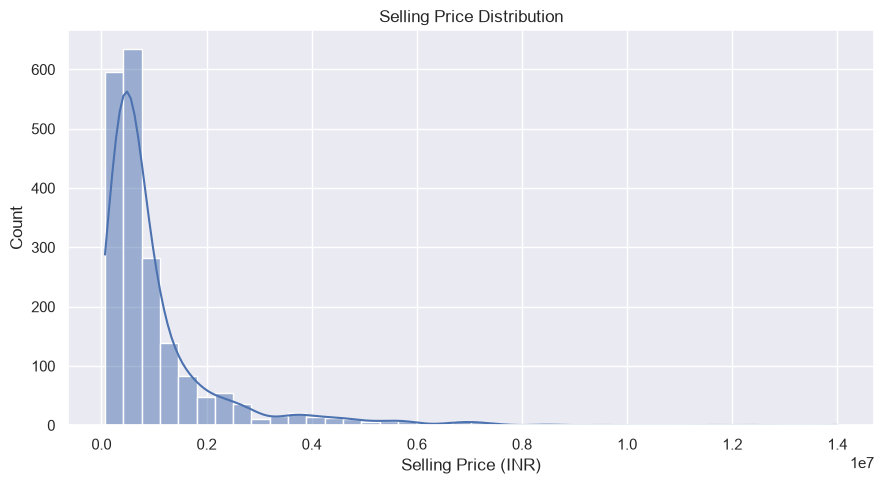

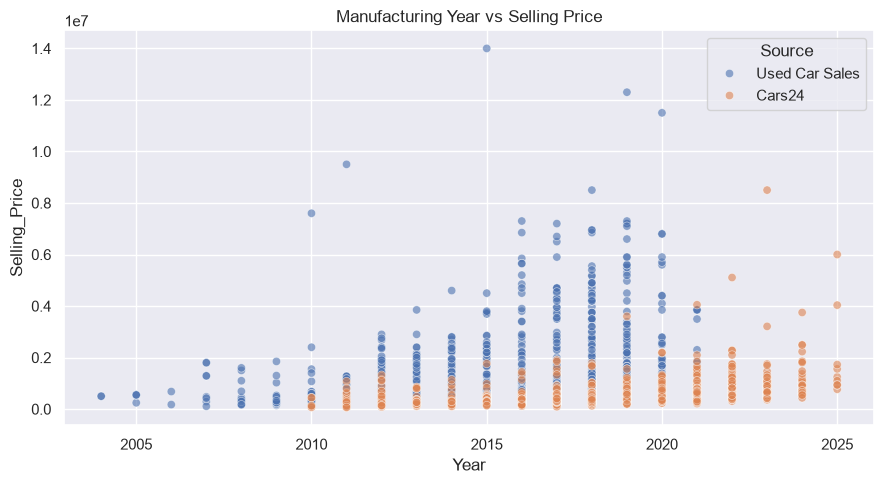

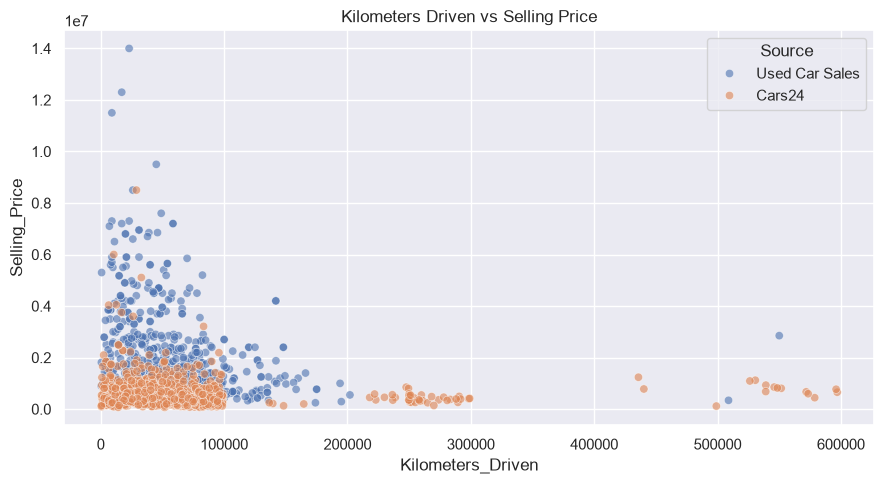

In [6]:
# Validate target and key numeric fields
assert (df["Selling_Price"] > 0).all(), "Non-positive target prices found"
assert (df["Kilometers_Driven"] >= 0).all(), "Negative odometer values found"
assert df["Year"].between(1990, 2025).all(), "Unexpected model year found"

plt.figure(figsize=(9, 5))
sns.histplot(df["Selling_Price"], bins=40, kde=True)
plt.title("Selling Price Distribution")
plt.xlabel("Selling Price (INR)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x="Year", y="Selling_Price", hue="Source", alpha=.6)
plt.title("Manufacturing Year vs Selling Price")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x="Kilometers_Driven", y="Selling_Price", hue="Source", alpha=.6)
plt.title("Kilometers Driven vs Selling Price")
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="Fuel_Type", y="Selling_Price")
plt.title("Selling Price by Fuel Type")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

display(df.groupby("Source")["Selling_Price"].describe())
display(df.groupby("Brand")["Selling_Price"].median().sort_values(ascending=False).head(15))

## Phase 5 – Prepare features and target

We exclude `Record_ID`, `Source_Record_ID`, and `Source` from model inputs because they are identifiers/provenance fields, not vehicle characteristics. `Selling_Price` is the target.

`Model` and `City` are retained as categorical features. The high-cardinality categorical columns will be encoded using one-hot encoding with infrequent-category grouping.

In [7]:
TARGET = "Selling_Price"
DROP_FROM_FEATURES = ["Record_ID", "Source_Record_ID", "Source", TARGET]

X = df.drop(columns=DROP_FROM_FEATURES)
y = df[TARGET].astype(float)

numeric_features = ["Year", "Kilometers_Driven"]
categorical_features = [
    "Brand", "Model", "City", "Fuel_Type", "Transmission"
]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Features:", X.columns.tolist())

X shape: (2000, 7)
y shape: (2000,)
Features: ['Brand', 'Model', 'Year', 'City', 'Kilometers_Driven', 'Fuel_Type', 'Transmission']


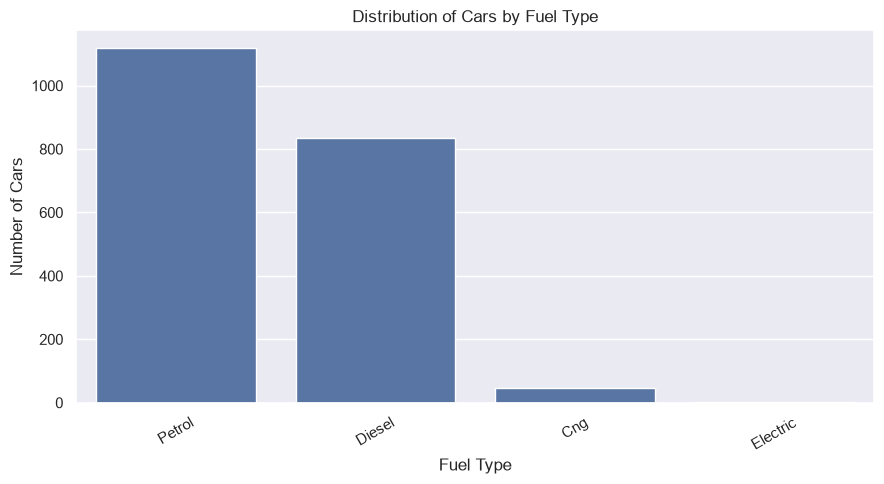

In [8]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Fuel_Type",
    order=df["Fuel_Type"].value_counts().index
)

plt.title("Distribution of Cars by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Number of Cars")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Phase 6 – Train/test split (80:20)

In [ ]:
from sklearn.model_selection import train_test_split

# Stratify by source so both data sources are represented in train and test.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=df["Source"]
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Training source distribution:")
display(df.loc[X_train.index, "Source"].value_counts())
print("Testing source distribution:")
display(df.loc[X_test.index, "Source"].value_counts())

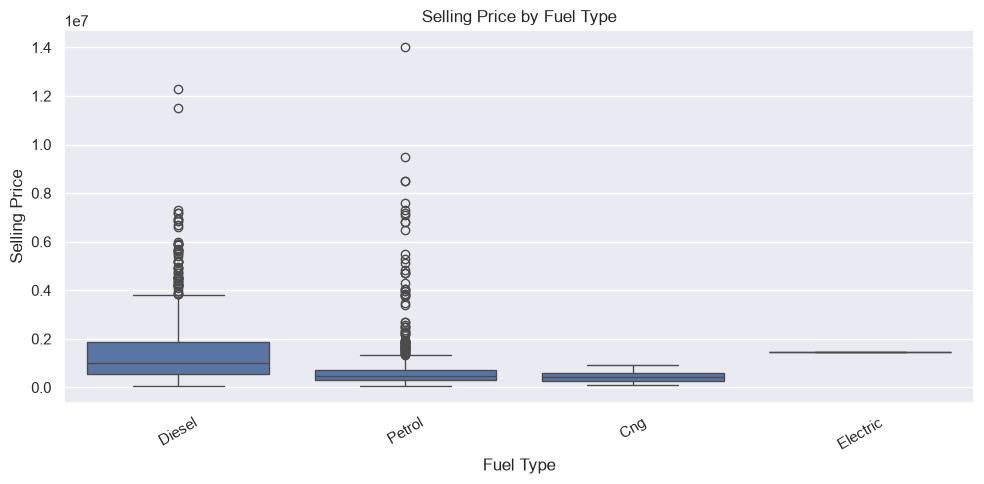

In [9]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="Fuel_Type",
    y="Selling_Price"
)

plt.title("Selling Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

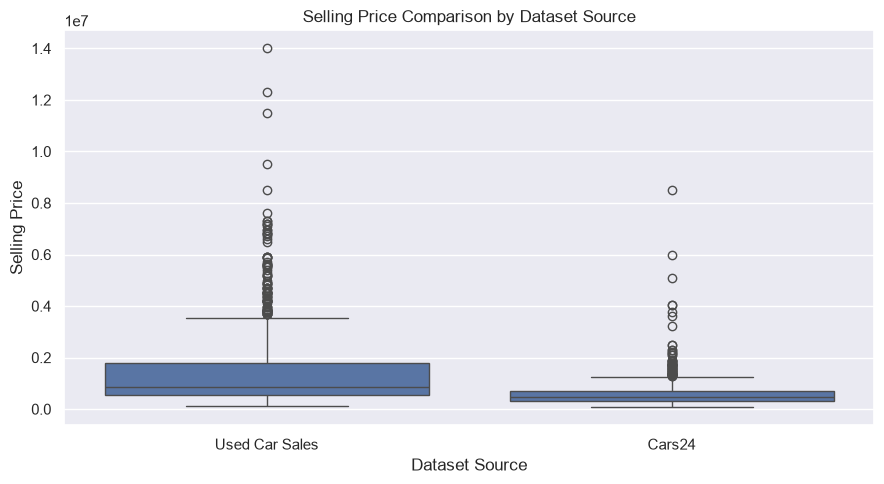

In [10]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Source",
    y="Selling_Price"
)

plt.title("Selling Price Comparison by Dataset Source")
plt.xlabel("Dataset Source")
plt.ylabel("Selling Price")
plt.tight_layout()
plt.show()

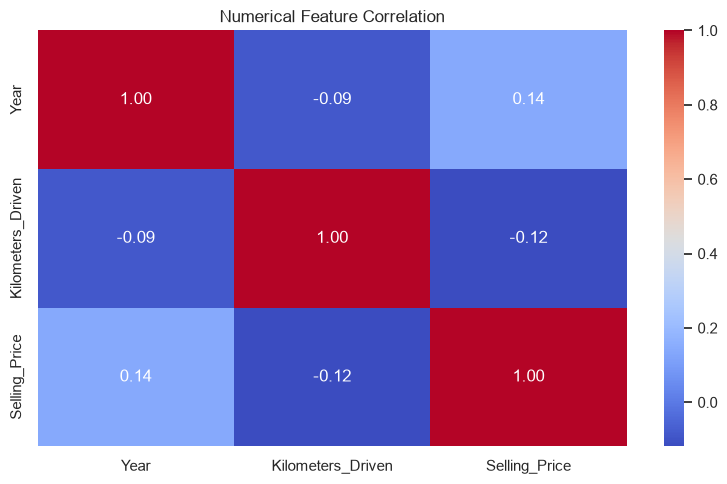

In [11]:
plt.figure(figsize=(8, 5))

numeric_data = df[
    ["Year", "Kilometers_Driven", "Selling_Price"]
]

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Numerical Feature Correlation")
plt.tight_layout()
plt.show()

In [12]:
print("Top 20 highest-priced vehicles:")

display(
    df.nlargest(20, "Selling_Price")[
        ["Brand", "Model", "Year",
         "Kilometers_Driven", "Selling_Price", "Source"]
    ]
)

Top 20 highest-priced vehicles:


,Brand,Model,Year,Kilometers_Driven,Selling_Price,Source
463,Mercedes-Benz,Mercedes-Benz G-Class G 63 AMG,2015,23000,14000000,Used Car Sales
505,Land Rover,Land Rover Range Rover Sport SE 3.0 Diesel [20...,2019,17000,12300000,Used Car Sales
816,Bmw,BMW 7 Series 730Ld DPE Signature,2020,9000,11500000,Used Car Sales
222,Bentley,Bentley Continental Flying Spur W12,2011,45000,9500000,Used Car Sales
188,Mercedes-Benz,Mercedes-Benz GLE Coupe 43 4MATIC [2017-2019],2018,26000,8500000,Used Car Sales
1270,Bmw,Z4 M40i M sport,2023,28878,8500000,Cars24
347,Bentley,Bentley Continental Flying Spur W12,2010,49000,7600000,Used Car Sales
472,Audi,Audi Q7 45 TDI Technology Pack,2019,9000,7300000,Used Car Sales
654,Ford,Ford Mustang GT Fastback 5.0L v8,2016,23000,7300000,Used Car Sales
258,Mercedes-Benz,Mercedes-Benz GLS 350 d,2019,58548,7200000,Used Car Sales


In [13]:
print("Top 20 highest-mileage vehicles:")

display(
    df.nlargest(20, "Kilometers_Driven")[
        ["Brand", "Model", "Year",
         "Kilometers_Driven", "Selling_Price", "Source"]
    ]
)

Top 20 highest-mileage vehicles:


,Brand,Model,Year,Kilometers_Driven,Selling_Price,Source
1337,Kia,SELTOS HTK PLUS 1.,2020,596978,655000,Cars24
1624,Kia,SONET HTX 1.,2021,596089,770000,Cars24
1280,Volkswagen,Vento HIGHLINE DIESEL 1.,2015,578742,442000,Cars24
1765,Kia,SELTOS HTK PLUS 1.,2020,573424,596000,Cars24
1595,Kia,SONET HTK PLUS 1.,2021,571830,669000,Cars24
1075,Kia,SONET HTX 1.,2021,551600,806000,Cars24
120,Audi,Audi Q5 3.0 TDI quattro Premium Plus,2015,550000,2850000,Used Car Sales
1682,Kia,SONET GTX PLUS 1.,2020,548478,819999,Cars24
1294,Kia,SELTOS HTK PLUS 1.,2021,545883,852999,Cars24
1176,Kia,SELTOS HTX PETROL 1.,2023,539139,928999,Cars24


In [16]:

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nTransmission values:")
print(df["Transmission"].value_counts(dropna=False))

print("\nSource distribution:")
print(df["Source"].value_counts())


Dataset shape: (2000, 11)

Columns:
['Record_ID', 'Brand', 'Model', 'Year', 'City', 'Kilometers_Driven', 'Fuel_Type', 'Transmission', 'Selling_Price', 'Source', 'Source_Record_ID']

Transmission values:
Transmission
Not available    1000
Manual            756
Automatic         244
Name: count, dtype: int64

Source distribution:
Source
Used Car Sales    1000
Cars24            1000
Name: count, dtype: int64


In [17]:

from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

cars24_path = PROJECT_ROOT / "original_data" / "cars24_clean_data.csv"

cars24_df = pd.read_csv(cars24_path)

print("Cars24 original columns:")
print(cars24_df.columns.tolist())

print("\nColumns containing transmission or drive:")
for column in cars24_df.columns:
    if "transmission" in column.lower() or "drive" in column.lower():
        print(f"\nColumn: {column}")
        print(cars24_df[column].value_counts(dropna=False).head(15))

print("\nFirst 5 Cars24 records:")
display(cars24_df.head())


Cars24 original columns:
['Brand', 'Variant', 'Model Year', 'City', 'Kilometer', 'EMI', 'Fuel_Type', 'Drive_Mode', 'Final_Price', 'Car_Age', 'KM_per_Year', 'Price_Segment', 'Age_Bucket']

Columns containing transmission or drive:

Column: Drive_Mode
Drive_Mode
Manual    2283
Auto       790
Name: count, dtype: int64

First 5 Cars24 records:


,Brand,Variant,Model Year,City,Kilometer,EMI,Fuel_Type,Drive_Mode,Final_Price,Car_Age,KM_per_Year,Price_Segment,Age_Bucket
0,Tata,Zest XE PETROL,2015,Hyderabad,55160,6824.0,Petrol,Manual,259000,11,5014.5,Budget,10+
1,Tata,NEXON XZA PLUS PETROL DUAL TONE,2019,Hyderabad,84719,8915.0,Petrol,Auto,505000,7,12102.7,Mid,7-10
2,Tata,TIGOR XZ (O) PETROL,2017,Hyderabad,34483,6762.0,Petrol,Manual,304000,9,3831.4,Budget,7-10
3,Tata,Nano TWIST XTA,2015,Hyderabad,46327,3982.0,Petrol,Auto,151000,11,4211.5,Budget,10+
4,Tata,Tiago XE DIESEL,2016,Hyderabad,98516,6847.0,Diesel,Manual,260000,10,9851.6,Budget,7-10


## Phase 7 – Preprocessing and model comparison

The preprocessing steps are fitted only on training folds through Scikit-learn pipelines. Numeric scaling is used for Linear Regression, SVR and KNN. Tree-based models use one-hot encoding without numeric scaling.

Algorithms:
1. Linear Regression
2. Decision Tree Regressor
3. Random Forest Regressor
4. Support Vector Regression
5. K-Nearest Neighbors Regressor
6. Gradient Boosting Regressor
7. XGBoost Regressor
8. Extra Trees Regressor

Model selection uses cross-validation on the training set. The test set is reserved for final evaluation.

In [ ]:

# ==========================================
# PHASE 7: MODEL TRAINING AND COMPARISON
# ==========================================

import pandas as pd
import numpy as np
import joblib

from pathlib import Path

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    ExtraTreesRegressor
)
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from xgboost import XGBRegressor


# ------------------------------------------
# 1. DEFINE FEATURES AND TARGET
# ------------------------------------------

TARGET = "Selling_Price"

DROP_COLUMNS = [
    "Record_ID",
    "Source_Record_ID",
    "Source"
]

X = df.drop(columns=[TARGET] + DROP_COLUMNS)
y = df[TARGET]

numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Features:", X.columns.tolist())
print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)


# ------------------------------------------
# 2. TRAIN-TEST SPLIT
# ------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=df["Source"]
)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))


# ------------------------------------------
# 3. DATA PREPROCESSING
# ------------------------------------------

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=5
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])


# ------------------------------------------
# 4. DEFINE ML ALGORITHMS
# ------------------------------------------

models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "SVR": SVR(),

    "KNN": KNeighborsRegressor(
        n_neighbors=5
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    ),

    "XGBoost": XGBRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=6,
        random_state=42,
        objective="reg:squarederror",
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )
}


# ------------------------------------------
# 5. CROSS-VALIDATION MODEL COMPARISON
# ------------------------------------------

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []
trained_pipelines = {}

for name, algorithm in models.items():

    print(f"\nTraining: {name}")

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", algorithm)
    ])

    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=1
    )

    mean_rmse = -scores.mean()

    results.append({
        "Model": name,
        "CV RMSE": mean_rmse,
        "CV Std": scores.std()
    })

    trained_pipelines[name] = pipeline

    print(f"Average CV RMSE: {mean_rmse:,.2f}")


# ------------------------------------------
# 6. COMPARE ALL MODELS
# ------------------------------------------

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="CV RMSE",
    ascending=True
).reset_index(drop=True)

print("\nMODEL PERFORMANCE COMPARISON")

display(results_df)


# ------------------------------------------
# 7. SELECT BEST MODEL
# ------------------------------------------

best_model_name = results_df.iloc[0]["Model"]

best_model = trained_pipelines[best_model_name]

print("\nBest Model:", best_model_name)


# ------------------------------------------
# 8. TRAIN BEST MODEL
# ------------------------------------------

best_model.fit(X_train, y_train)

print("Best model training completed!")


# ------------------------------------------
# 9. TEST MODEL PERFORMANCE
# ------------------------------------------

y_pred = best_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("\nFINAL MODEL EVALUATION")
print("------------------------------")
print("Selected Model:", best_model_name)
print(f"MAE:  {mae:,.2f}")
print(f"MSE:  {mse:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"R2 Score: {r2:.4f}")


# ------------------------------------------
# 10. SAVE TRAINED MODEL
# ------------------------------------------

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

MODEL_DIR = PROJECT_ROOT / "models"

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

MODEL_PATH = MODEL_DIR / "best_model.joblib"

joblib.dump(best_model, MODEL_PATH)

print("\nMODEL SAVED SUCCESSFULLY!")
print("Saved location:", MODEL_PATH)


# ------------------------------------------
# 11. VERIFY SAVED MODEL
# ------------------------------------------

loaded_model = joblib.load(MODEL_PATH)

test_prediction = loaded_model.predict(
    X_test.iloc[[0]]
)

print("\nModel verification successful!")
print("Sample predicted price:", test_prediction[0])
print("Actual price:", y_test.iloc[0])


In [ ]:

# ============================================================
# PHASE 7: MODEL TRAINING AND ALGORITHM COMPARISON
# Used Car Price Prediction
# ============================================================


# ------------------------------------------------------------
# 1. IMPORT LIBRARIES
# ------------------------------------------------------------

import pandas as pd
import numpy as np
import joblib

from pathlib import Path

from sklearn.model_selection import train_test_split, KFold, cross_val_score

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    ExtraTreesRegressor
)

from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


# ------------------------------------------------------------
# 2. CHECK XGBOOST AVAILABILITY
# ------------------------------------------------------------

try:
    from xgboost import XGBRegressor

    xgboost_available = True

    print("XGBoost is available!")

except ImportError:

    xgboost_available = False

    print("XGBoost is not installed. Skipping XGBoost.")


# ------------------------------------------------------------
# 3. DEFINE FEATURES AND TARGET
# ------------------------------------------------------------

TARGET = "Selling_Price"

# Remove identifiers and source information.
# These columns should not be used as model features.

DROP_COLUMNS = [
    "Record_ID",
    "Source_Record_ID",
    "Source"
]

X = df.drop(
    columns=[TARGET] + DROP_COLUMNS,
    errors="ignore"
)

y = df[TARGET]


# Identify numerical and categorical features.

numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()


print("\nFEATURE INFORMATION")
print("------------------------------")

print("Total Features:", len(X.columns))

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)


# ------------------------------------------------------------
# 4. TRAIN-TEST SPLIT
# ------------------------------------------------------------

# 80% training data
# 20% testing data

# Stratification maintains the source proportions
# in both training and testing datasets.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=df["Source"]
)


print("\nDATA SPLITTING")
print("------------------------------")

print("Total Records:", len(df))
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))


# ------------------------------------------------------------
# 5. CREATE PREPROCESSING FUNCTION
# ------------------------------------------------------------

def make_preprocessor(scale_numeric=True):

    # Numerical preprocessing

    numeric_transformer = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(strategy="median")
            ),

            *(
                [("scaler", StandardScaler())]
                if scale_numeric else []
            )
        ]
    )

    # Categorical preprocessing

    categorical_transformer = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(strategy="most_frequent")
            ),

            (
                "onehot",
                OneHotEncoder(
                    handle_unknown="ignore",
                    min_frequency=5
                )
            )
        ]
    )

    # Combine both transformers

    return ColumnTransformer(
        transformers=[
            (
                "num",
                numeric_transformer,
                numeric_features
            ),

            (
                "cat",
                categorical_transformer,
                categorical_features
            )
        ]
    )


# ------------------------------------------------------------
# 6. DEFINE MACHINE LEARNING ALGORITHMS
# ------------------------------------------------------------

models = {

    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42,
        min_samples_leaf=2
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    "SVR": SVR(
        C=10,
        epsilon=0.1,
        kernel="rbf"
    ),

    "KNN": KNeighborsRegressor(
        n_neighbors=7,
        weights="distance"
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    )
}


# Add XGBoost only if available.

if xgboost_available:

    models["XGBoost"] = XGBRegressor(

        n_estimators=300,

        max_depth=5,

        learning_rate=0.05,

        subsample=0.9,

        colsample_bytree=0.9,

        objective="reg:squarederror",

        random_state=42,

        n_jobs=-1
    )


print("\nALGORITHMS SELECTED")
print("------------------------------")

for model_name in models:
    print("-", model_name)

print("\nTotal Algorithms:", len(models))


# ------------------------------------------------------------
# 7. DEFINE SCALING REQUIREMENTS
# ------------------------------------------------------------

# These algorithms benefit from numerical scaling.

scaled_models = {
    "Linear Regression",
    "SVR",
    "KNN"
}


# ------------------------------------------------------------
# 8. CONFIGURE CROSS-VALIDATION
# ------------------------------------------------------------

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# ------------------------------------------------------------
# 9. TRAIN AND COMPARE MODELS
# ------------------------------------------------------------

results = []

pipelines = {}


for name, estimator in models.items():

    print("\n" + "=" * 55)

    print("Training:", name)

    # Create preprocessing and model pipeline.

    pipeline = Pipeline(
        steps=[
            (
                "preprocessor",
                make_preprocessor(
                    scale_numeric=(name in scaled_models)
                )
            ),

            (
                "model",
                estimator
            )
        ]
    )

    # Perform 5-fold cross-validation.

    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=1
    )

    # Convert negative RMSE into positive RMSE.

    mean_rmse = -scores.mean()

    std_rmse = scores.std()

    # Store performance results.

    results.append({

        "Algorithm": name,

        "CV_RMSE_Mean": mean_rmse,

        "CV_RMSE_Std": std_rmse

    })

    # Store pipeline for later training.

    pipelines[name] = pipeline

    print("Average CV RMSE:", round(mean_rmse, 2))

    print("RMSE Standard Deviation:", round(std_rmse, 2))


# ------------------------------------------------------------
# 10. DISPLAY MODEL COMPARISON
# ------------------------------------------------------------

cv_results = pd.DataFrame(results)

cv_results = cv_results.sort_values(
    by="CV_RMSE_Mean",
    ascending=True
).reset_index(drop=True)


print("\nMODEL PERFORMANCE COMPARISON")

display(cv_results)


# ------------------------------------------------------------
# 11. SELECT THE BEST MODEL
# ------------------------------------------------------------

best_model_name = cv_results.iloc[0]["Algorithm"]

best_model = pipelines[best_model_name]


print("\nBEST MODEL SELECTED")
print("------------------------------")

print("Algorithm:", best_model_name)

print(
    "Cross-validation RMSE:",
    round(cv_results.iloc[0]["CV_RMSE_Mean"], 2)
)


# ------------------------------------------------------------
# 12. TRAIN BEST MODEL ON COMPLETE TRAINING DATA
# ------------------------------------------------------------

best_model.fit(
    X_train,
    y_train
)


print("\nBest model training completed successfully!")


# ------------------------------------------------------------
# 13. PREDICT TEST DATA
# ------------------------------------------------------------

y_pred = best_model.predict(X_test)


# ------------------------------------------------------------
# 14. EVALUATE MODEL PERFORMANCE
# ------------------------------------------------------------

mae = mean_absolute_error(
    y_test,
    y_pred
)

mse = mean_squared_error(
    y_test,
    y_pred
)

rmse = np.sqrt(mse)

r2 = r2_score(
    y_test,
    y_pred
)


print("\nFINAL MODEL EVALUATION")
print("=" * 55)

print("Best Algorithm:", best_model_name)

print(f"MAE  : {mae:,.2f}")

print(f"MSE  : {mse:,.2f}")

print(f"RMSE : {rmse:,.2f}")

print(f"R2 Score: {r2:.4f}")


# ------------------------------------------------------------
# 15. CREATE ACTUAL VS PREDICTED COMPARISON
# ------------------------------------------------------------

comparison_df = pd.DataFrame({

    "Actual Price": y_test.values,

    "Predicted Price": y_pred

})

comparison_df["Difference"] = (
    comparison_df["Actual Price"]
    - comparison_df["Predicted Price"]
)

display(comparison_df.head(20))


# ------------------------------------------------------------
# 16. SAVE TRAINED MODEL
# ------------------------------------------------------------

PROJECT_ROOT = Path.cwd()

# Handle execution from the notebooks folder.

if PROJECT_ROOT.name == "notebooks":

    PROJECT_ROOT = PROJECT_ROOT.parent


MODEL_DIR = PROJECT_ROOT / "models"

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)


MODEL_PATH = MODEL_DIR / "best_model.joblib"


# Save complete pipeline, including preprocessing.

joblib.dump(
    best_model,
    MODEL_PATH
)


print("\nMODEL SAVED SUCCESSFULLY")
print("=" * 55)

print("Model Name:", best_model_name)

print("Model Location:", MODEL_PATH)


# ------------------------------------------------------------
# 17. VERIFY SAVED MODEL
# ------------------------------------------------------------

loaded_model = joblib.load(MODEL_PATH)


sample_input = X_test.iloc[[0]]

sample_prediction = loaded_model.predict(
    sample_input
)[0]


print("\nMODEL VERIFICATION")
print("------------------------------")

print("Model loaded successfully!")

print(f"Actual Price: ₹ {y_test.iloc[0]:,.2f}")

print(f"Predicted Price: ₹ {sample_prediction:,.2f}")


print("\nPHASE 7 COMPLETED SUCCESSFULLY!")


## Phase 8 – Train the selected model and evaluate on the test set

In [ ]:
best_name = cv_results.iloc[0]["Algorithm"]
best_pipeline = pipelines[best_name]
best_pipeline.fit(X_train, y_train)

test_predictions = best_pipeline.predict(X_test)

mae = mean_absolute_error(y_test, test_predictions)
mse = mean_squared_error(y_test, test_predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, test_predictions)

print("Selected model:", best_name)
print(f"MAE:  ₹{mae:,.2f}")
print(f"MSE:  {mse:,.2f}")
print(f"RMSE: ₹{rmse:,.2f}")
print(f"R²:   {r2:.4f}")

In [ ]:
comparison = pd.DataFrame({
    "Actual_Price": y_test,
    "Predicted_Price": test_predictions
})
display(comparison.head(15))

plt.figure(figsize=(7, 7))
sns.scatterplot(x=y_test, y=test_predictions, alpha=.6)
min_v = min(y_test.min(), test_predictions.min())
max_v = max(y_test.max(), test_predictions.max())
plt.plot([min_v, max_v], [min_v, max_v], linestyle="--")
plt.xlabel("Actual Selling Price (INR)")
plt.ylabel("Predicted Selling Price (INR)")
plt.title("Actual vs Predicted Prices")
plt.tight_layout()
plt.show()

## Phase 9 – Save the selected model

In [ ]:
import joblib
from pathlib import Path

model_dir = Path("../models")
if not model_dir.exists():
    model_dir = Path("models")
model_dir.mkdir(parents=True, exist_ok=True)

model_path = model_dir / "best_model.joblib"
joblib.dump(best_pipeline, model_path)
print("Saved model to:", model_path.resolve())

## Phase 10 – Next development task: prediction interface

After reviewing the model results, build a Gradio interface that collects the same feature fields used during training:

- Brand
- Model
- Year
- City
- Kilometers driven
- Fuel type
- Transmission

The interface should clearly state that the result is an estimated price, not a guaranteed market valuation. Do not build the interface until the model and input schema have been verified.